# Consignas 2.2 y 2.3 Clasificación de CIFAR10 con una CNN
**Matias Agustin Elizaincin · Sistemas Inteligentes · Universidad CAECE**

Este cuaderno sigue los incisos 2.3.a a 2.3.g en orden y ejecuta tres entrenamientos
independientes de **15, 30 y 50 épocas**, todos desde cero. No se usa EarlyStopping porque
se deben completar las cantidades solicitadas. Se mantienen arquitectura y tasa de aprendizaje.

**Ejecución conservada:** completada en Google Colab el 20 de noviembre de 2026 con GPU disponible; las salidas y los resultados corresponden a esa ejecución.
En Colab elegir **GPU T4** antes de ejecutar todas las celdas; guardar el cuaderno con sus salidas
y descargar el ZIP final. La duración depende del dispositivo realmente asignado.


## 2.2 Características del conjunto
**a)** CIFAR-10 tiene 60.000 imágenes: 50.000 de entrenamiento y 10.000 de prueba.
Hay 6.000 por clase: 5.000 de entrenamiento y 1.000 de prueba. Los archivos originales
se organizan en cinco lotes de entrenamiento de 10.000 y un lote de prueba de 10.000.

**b)** Las imágenes son RGB de 32 × 32 píxeles, con tres canales, y corresponden a diez clases mutuamente excluyentes.

**c)** Los píxeles originales son uint8 entre 0 y 255; cada imagen contiene 3.072 valores.
Las etiquetas enteras van de 0 a 9 y Keras las entrega con forma (N,1). Las imágenes presentan
variaciones de fondo, pose e iluminación; la baja resolución y la semejanza entre categorías
dificultan la clasificación. El reparto balanceado no asegura igual dificultad por clase.

Fuente primaria: Krizhevsky, A., Nair, V., y Hinton, G. *The CIFAR-10 dataset*.
https://www.cs.toronto.edu/~kriz/cifar.html


## 2.3.a Importaciones necesarias


In [1]:
import os, json, time, platform, sys, shutil, hashlib
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from IPython.display import display

SEMILLA = 2026
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()
if 'google.colab' in sys.modules:
    BASE = Path('/content/Actividad_Integradora')
elif '__file__' in globals():
    BASE = Path(__file__).resolve().parents[1] / '02_Resultados'
else:
    actual = Path.cwd().resolve()
    candidatos = [actual/'Actividades'/'Actividad Integradora', actual/'Actividad Integradora', actual.parent, actual]
    raiz = next((p for p in candidatos if (p/'01_Cuadernos').is_dir()), actual)
    BASE = raiz / '02_Resultados'
BASE.mkdir(parents=True, exist_ok=True)
print('TensorFlow:', tf.__version__, 'NumPy:', np.__version__)
print('GPU disponibles:', tf.config.list_physical_devices('GPU'))
print('Directorio de resultados:', BASE.resolve())


TensorFlow: 2.21.0 NumPy: 2.4.6
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Directorio de resultados: /content/Actividad_Integradora


## 2.3.b Descarga y separación oficial
`datasets.cifar10.load_data()` devuelve juntos los pares de entrenamiento y prueba, ya separados.
Se conserva el conjunto de prueba oficial completo; la validación se extrae del entrenamiento.


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
assert train_images.shape == (50000,32,32,3)
assert test_images.shape == (10000,32,32,3)
assert train_labels.shape == (50000,1) and test_labels.shape == (10000,1)
print('Entrenamiento:',train_images.shape,train_labels.shape)
print('Prueba:',test_images.shape,test_labels.shape)
print('Por clase (train):',np.bincount(train_labels.reshape(-1)))
print('Por clase (test):',np.bincount(test_labels.reshape(-1)))
CARPETA=BASE/'CIFAR10'; CARPETA.mkdir(exist_ok=True)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1301s 8us/step
Entrenamiento: (50000, 32, 32, 3) (50000, 1)
Prueba: (10000, 32, 32, 3) (10000, 1)
Por clase (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Por clase (test): [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## 2.3.c Normalización de píxeles al intervalo 0 a 1


In [3]:
train_images=train_images.astype('float32')/255.0
test_images=test_images.astype('float32')/255.0
assert train_images.min()>=0 and train_images.max()<=1
assert test_images.min()>=0 and test_images.max()<=1
print('Rango:',float(train_images.min()),float(train_images.max()))


Rango: 0.0 1.0


## 2.3.d Primeras 25 imágenes del entrenamiento con su clase


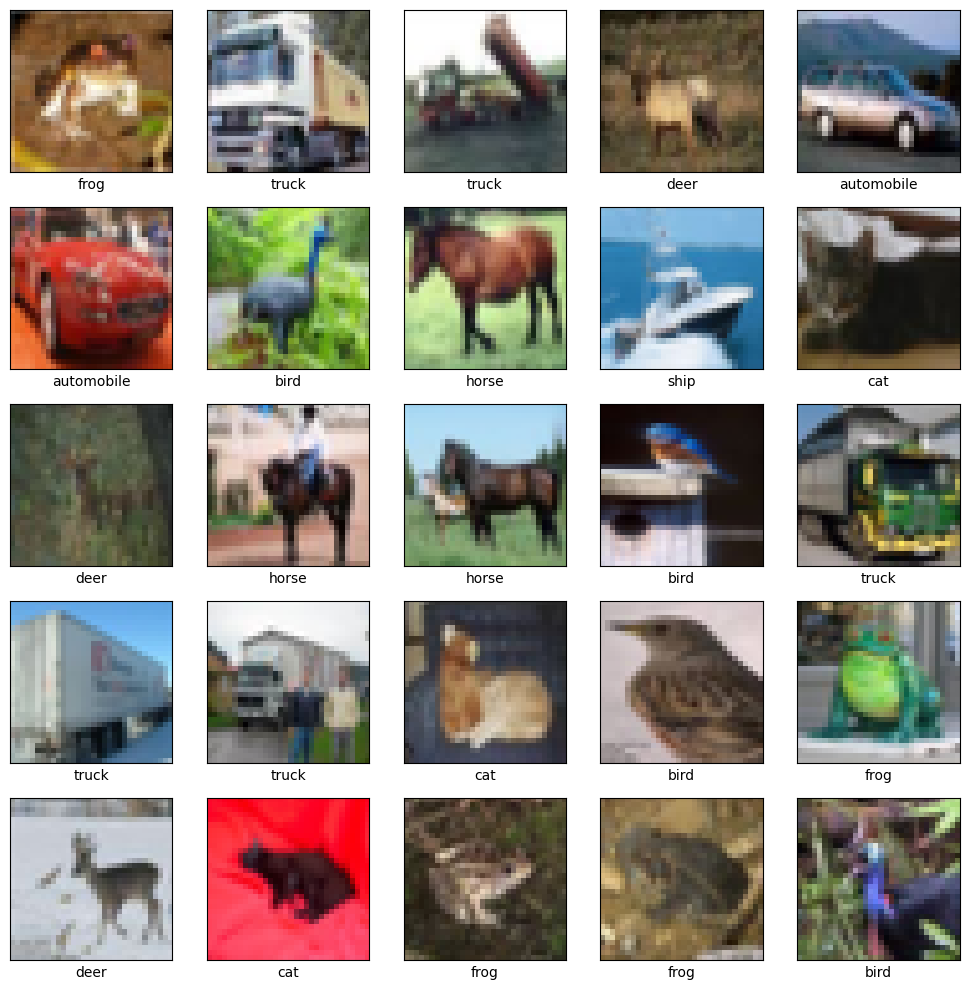

In [4]:
class_names=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.tight_layout(); plt.savefig(CARPETA/'primeras_25.png',dpi=180); plt.show()


## 2.3.e Arquitectura y entrenamiento
La entrada **(32,32,3)** representa alto, ancho y tres canales RGB; el tamaño del lote no se incluye.
`Input(shape=...)` declara la misma forma que `input_shape` en la primera convolución y evita advertencias de Keras.
Se conservan exactamente las convoluciones 32, 64 y 64, kernels 3 × 3, ReLU, dos MaxPool de 2 × 2,
Flatten, Dense de 64 con ReLU y salida de 10 neuronas. El padding es `valid` y el stride es 1.

La salida contiene **logits**, por lo que la pérdida es `SparseCategoricalCrossentropy(from_logits=True)`.
No se convierten las etiquetas a one-hot. Adam usa tasa 0,001 y accuracy mide la fracción de aciertos.


In [5]:
def crear_cifar10():
    return models.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.Conv2D(32,(3,3),activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64,(3,3),activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64,(3,3),activation='relu'),
        layers.Flatten(),
        layers.Dense(64,activation='relu'),
        layers.Dense(10)
    ],name='CNN_CIFAR10_consigna')

model=crear_cifar10()
model.summary()
assert model.count_params()==122570
assert model.output_shape==(None,10)


Model: "CNN_CIFAR10_consigna"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
def particion_estratificada(y, cantidad_por_clase, seed=SEMILLA):
    # La validación sale exclusivamente del entrenamiento oficial.
    rng = np.random.default_rng(seed)
    entrenamiento, validacion = [], []
    for clase in range(10):
        indices = np.flatnonzero(y.reshape(-1) == clase)
        rng.shuffle(indices)
        validacion.extend(indices[:cantidad_por_clase])
        entrenamiento.extend(indices[cantidad_por_clase:])
    entrenamiento, validacion = np.array(entrenamiento), np.array(validacion)
    rng.shuffle(entrenamiento)
    rng.shuffle(validacion)
    assert len(np.intersect1d(entrenamiento, validacion)) == 0
    assert len(entrenamiento)+len(validacion) == len(y)
    return entrenamiento, validacion

def lotes(x, y, batch_size=128, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if entrenamiento:
        ds = ds.shuffle(len(x), seed=SEMILLA, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def graficar_historial(historia, nombre, carpeta):
    epocas = np.arange(1, len(historia['loss'])+1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for clave, titulo, eje in [('accuracy','Exactitud',ax[0]), ('loss','Pérdida',ax[1])]:
        eje.plot(epocas, historia[clave], label='Entrenamiento')
        eje.plot(epocas, historia['val_'+clave], label='Validación')
        eje.set(xlabel='Época', ylabel=titulo, title=titulo)
        eje.grid(alpha=.25); eje.legend()
    ax[0].set_ylim(0, 1)
    fig.suptitle(nombre); fig.tight_layout()
    fig.savefig(carpeta/f'{nombre}_curvas.png', dpi=180)
    plt.show()

def guardar_entorno(carpeta):
    info = {'fecha_utc': datetime.now(timezone.utc).isoformat(), 'python':sys.version,
            'plataforma':platform.platform(), 'semilla':SEMILLA,
            'dispositivos':[str(d) for d in tf.config.list_physical_devices()],
            'paquetes':{p:metadata.version(p) for p in ['tensorflow','keras','numpy','pandas','matplotlib']}}
    (carpeta/'entorno.json').write_text(json.dumps(info,indent=2,ensure_ascii=False),encoding='utf-8')

def firma_experimento(modelo, epocas, arrays):
    # El respaldo solo se reutiliza si coinciden datos, arquitectura y configuración.
    config = {'protocolo': 'CNN-2026-v2', 'semilla': SEMILLA, 'epocas': epocas,
              'batch_size': 128, 'adam_learning_rate': 0.001,
              'tensorflow': tf.__version__, 'keras': metadata.version('keras'),
              'arquitectura': json.loads(modelo.to_json()), 'datos': []}
    for a in arrays:
        a = np.ascontiguousarray(a)
        config['datos'].append({'forma': list(a.shape), 'dtype': str(a.dtype),
                               'sha256': hashlib.sha256(memoryview(a).cast('B')).hexdigest()})
    return hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()

def entrenar(nombre, constructor, epocas, x_train, y_train, x_val, y_val, carpeta):
    # Cada experimento empieza desde cero con el mismo split y la misma semilla.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo = constructor()
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                   loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                   metrics=['accuracy'])
    firma = firma_experimento(modelo, epocas, (x_train,y_train,x_val,y_val))
    archivo = carpeta/f'{nombre}.keras'
    respaldo = carpeta/f'{nombre}_registro.json'
    historial = carpeta/f'{nombre}_historia.json'
    if respaldo.exists() and archivo.exists() and historial.exists():
        previo = json.loads(respaldo.read_text(encoding='utf-8'))
        if previo.get('firma') == firma:
            datos = json.loads(historial.read_text(encoding='utf-8'))
            assert all(len(datos[k]) == epocas for k in ['loss','accuracy','val_loss','val_accuracy'])
            assert all(np.isfinite(v).all() for v in datos.values())
            assert hashlib.sha256(archivo.read_bytes()).hexdigest() == previo['modelo_sha256']
            restaurado = tf.keras.models.load_model(archivo)
            assert restaurado.count_params() == modelo.count_params()
            print('Corrida completa recuperada sin repetir entrenamiento:', nombre)
            if not (carpeta/f'{nombre}_curvas.png').exists():
                graficar_historial(datos,nombre,carpeta)
            return previo['registro']
    print('\nExperimento:',nombre,'| Épocas:',epocas)
    modelo.summary()
    resumen=[]; modelo.summary(print_fn=lambda s:resumen.append(s))
    (carpeta/f'{nombre}_arquitectura.txt').write_text('\n'.join(resumen),encoding='utf-8')
    callbacks=[tf.keras.callbacks.CSVLogger(str(carpeta/f'{nombre}_epocas.csv')),
               tf.keras.callbacks.TerminateOnNaN()]
    inicio=time.perf_counter()
    historia=modelo.fit(lotes(x_train,y_train,entrenamiento=True),
                        validation_data=lotes(x_val,y_val), epochs=epocas,
                        callbacks=callbacks, verbose=2)
    duracion=time.perf_counter()-inicio
    assert len(historia.history['loss']) == epocas, 'El entrenamiento terminó antes de lo solicitado.'
    assert all(np.isfinite(v).all() for v in historia.history.values())
    modelo.save(archivo)
    registro={'experimento':nombre, 'epocas':epocas,'parametros':modelo.count_params(),
              'duracion_segundos':duracion, 'archivo_modelo':archivo.name,
              **{k:float(v[-1]) for k,v in historia.history.items()}}
    (carpeta/f'{nombre}_historia.json').write_text(json.dumps(historia.history,indent=2),encoding='utf-8')
    respaldo.write_text(json.dumps({'firma': firma, 'estado': 'corrida_completa',
        'modelo_sha256': hashlib.sha256(archivo.read_bytes()).hexdigest(),
        'registro': registro},indent=2,ensure_ascii=False),encoding='utf-8')
    graficar_historial(historia.history,nombre,carpeta)
    return registro

def evaluar(nombre, x_test, y_test, carpeta):
    modelo=tf.keras.models.load_model(carpeta/f'{nombre}.keras')
    perd,acc=modelo.evaluate(lotes(x_test,y_test),verbose=2)
    logits=modelo.predict(lotes(x_test,y_test),verbose=0)
    prob=tf.nn.softmax(logits,axis=1).numpy()
    pred=prob.argmax(axis=1)
    assert np.allclose(prob.sum(axis=1),1,atol=1e-6)
    assert np.isclose(np.mean(pred==y_test.reshape(-1)),acc,atol=1e-6)
    pd.DataFrame({'indice':np.arange(len(pred)),'clase_real':y_test.reshape(-1),
                  'clase_predicha':pred,'probabilidad_maxima':prob.max(axis=1)}).to_csv(carpeta/f'{nombre}_predicciones.csv',index=False)
    return {'experimento':nombre,'test_loss':float(perd),'test_accuracy':float(acc)}, prob

def exportar(carpeta):
    archivo=shutil.make_archive(str(carpeta), 'zip', root_dir=carpeta)
    print('Resultados guardados:',archivo)
    try:
        from google.colab import files
    except ImportError:
        return
    files.download(archivo)


### Validación independiente y control experimental
Se reservan 500 imágenes por clase del entrenamiento: 45.000 para ajustar pesos y 5.000 para validar.
El test conserva sus 10.000 imágenes. Los tres experimentos usan exactamente los mismos índices,
semilla y lotes de 128; cada uno reinicia modelo y optimizador. Los tres llegan al número de épocas fijado.
El modelo se selecciona por la menor pérdida de validación **al final del entrenamiento**, sin usar test.



Experimento: CIFAR10_15_epocas | Épocas: 15


Model: "CNN_CIFAR10_consigna"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
352/352 - 10s - 28ms/step - accuracy: 0.3804 - loss: 1.6922 - val_accuracy: 0.4684 - val_loss: 1.4636
Epoch 2/15
352/352 - 5s - 15ms/step - accuracy: 0.5073 - loss: 1.3708 - val_accuracy: 0.5402 - val_loss: 1.3278
Epoch 3/15
352/352 - 3s - 9ms/step - accuracy: 0.5651 - loss: 1.2272 - val_accuracy: 0.5922 - val_loss: 1.1658
Epoch 4/15
352/352 - 3s - 10ms/step - accuracy: 0.6087 - loss: 1.1103 - val_accuracy: 0.6106 - val_loss: 1.1257
Epoch 5/15
352/352 - 3s - 8ms/step - accuracy: 0.6366 - loss: 1.0370 - val_accuracy: 0.6380 - val_loss: 1.0398
Epoch 6/15
352/352 - 3s - 9ms/step - accuracy: 0.6613 - loss: 0.9690 - val_accuracy: 0.6442 - val_loss: 1.0220
Epoch 7/15
352/352 - 3s - 10ms/step - accuracy: 0.6793 - loss: 0.9170 - val_accuracy: 0.6640 - val_loss: 0.9612
Epoch 8/15
352/352 - 3s - 10ms/step - accuracy: 0.6973 - loss: 0.8718 - val_accuracy: 0.6660 - val_loss: 0.9500
Epoch 9/15
352/352 - 3s - 8ms/step - accuracy: 0.7100 - loss: 0.8352 - val_accuracy: 0.6518 - val_loss: 1.

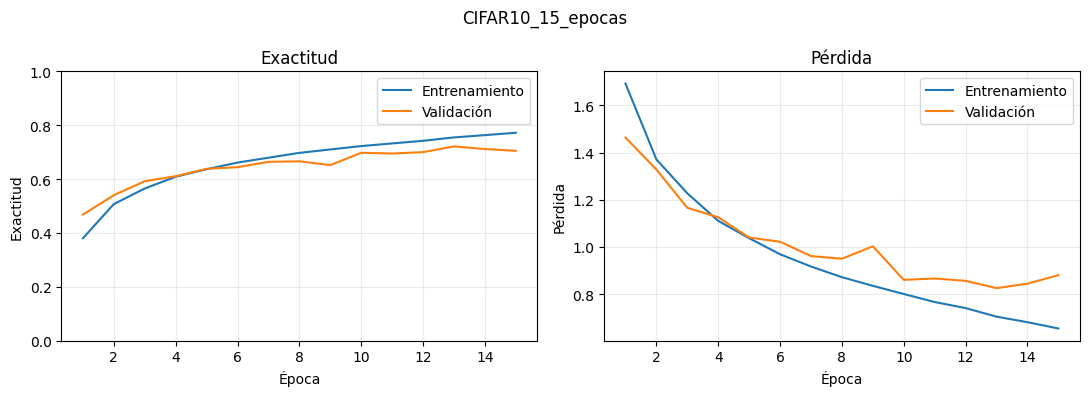


Experimento: CIFAR10_30_epocas | Épocas: 30


Model: "CNN_CIFAR10_consigna"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
352/352 - 5s - 15ms/step - accuracy: 0.3804 - loss: 1.6922 - val_accuracy: 0.4684 - val_loss: 1.4636
Epoch 2/30
352/352 - 4s - 10ms/step - accuracy: 0.5073 - loss: 1.3708 - val_accuracy: 0.5402 - val_loss: 1.3278
Epoch 3/30
352/352 - 5s - 13ms/step - accuracy: 0.5651 - loss: 1.2272 - val_accuracy: 0.5922 - val_loss: 1.1658
Epoch 4/30
352/352 - 3s - 8ms/step - accuracy: 0.6087 - loss: 1.1103 - val_accuracy: 0.6106 - val_loss: 1.1257
Epoch 5/30
352/352 - 5s - 16ms/step - accuracy: 0.6366 - loss: 1.0370 - val_accuracy: 0.6380 - val_loss: 1.0398
Epoch 6/30
352/352 - 3s - 8ms/step - accuracy: 0.6613 - loss: 0.9690 - val_accuracy: 0.6442 - val_loss: 1.0220
Epoch 7/30
352/352 - 3s - 8ms/step - accuracy: 0.6793 - loss: 0.9170 - val_accuracy: 0.6640 - val_loss: 0.9612
Epoch 8/30
352/352 - 3s - 10ms/step - accuracy: 0.6973 - loss: 0.8718 - val_accuracy: 0.6660 - val_loss: 0.9500
Epoch 9/30
352/352 - 3s - 9ms/step - accuracy: 0.7100 - loss: 0.8352 - val_accuracy: 0.6518 - val_loss: 1.0

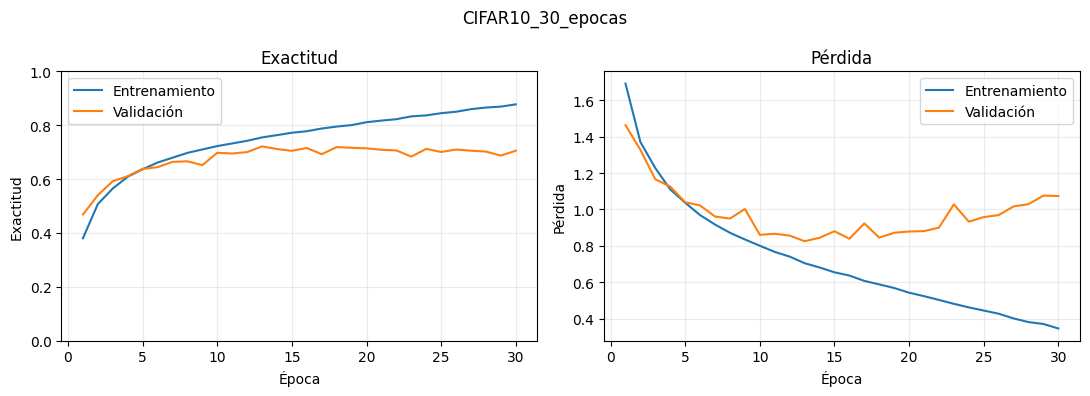


Experimento: CIFAR10_50_epocas | Épocas: 50


Model: "CNN_CIFAR10_consigna"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
352/352 - 5s - 14ms/step - accuracy: 0.3804 - loss: 1.6922 - val_accuracy: 0.4684 - val_loss: 1.4636
Epoch 2/50
352/352 - 6s - 16ms/step - accuracy: 0.5073 - loss: 1.3708 - val_accuracy: 0.5402 - val_loss: 1.3278
Epoch 3/50
352/352 - 3s - 8ms/step - accuracy: 0.5651 - loss: 1.2272 - val_accuracy: 0.5922 - val_loss: 1.1658
Epoch 4/50
352/352 - 3s - 8ms/step - accuracy: 0.6087 - loss: 1.1103 - val_accuracy: 0.6106 - val_loss: 1.1257
Epoch 5/50
352/352 - 3s - 8ms/step - accuracy: 0.6366 - loss: 1.0370 - val_accuracy: 0.6380 - val_loss: 1.0398
Epoch 6/50
352/352 - 4s - 11ms/step - accuracy: 0.6613 - loss: 0.9690 - val_accuracy: 0.6442 - val_loss: 1.0220
Epoch 7/50
352/352 - 3s - 8ms/step - accuracy: 0.6793 - loss: 0.9170 - val_accuracy: 0.6640 - val_loss: 0.9612
Epoch 8/50
352/352 - 3s - 8ms/step - accuracy: 0.6973 - loss: 0.8718 - val_accuracy: 0.6660 - val_loss: 0.9500
Epoch 9/50
352/352 - 3s - 9ms/step - accuracy: 0.7100 - loss: 0.8352 - val_accuracy: 0.6518 - val_loss: 1.002

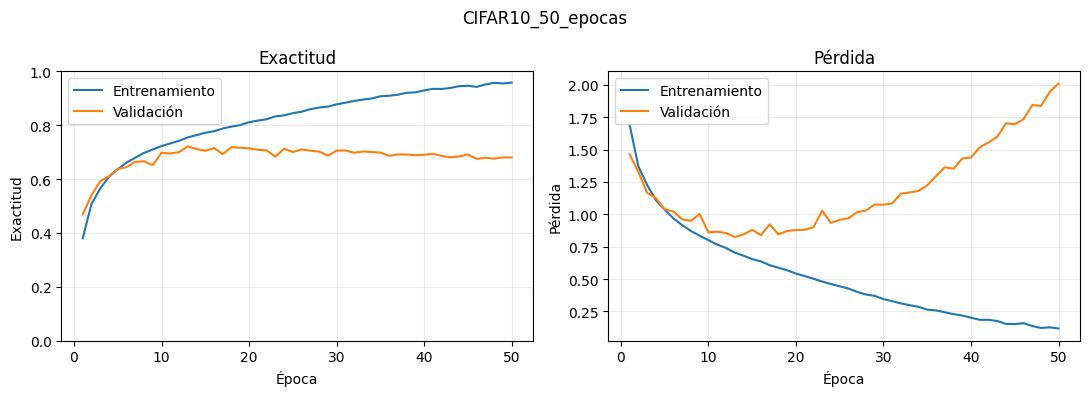

,experimento,epocas,parametros,duracion_segundos,archivo_modelo,accuracy,loss,val_accuracy,val_loss
0,CIFAR10_15_epocas,15,122570,62.391576,CIFAR10_15_epocas.keras,0.772000,0.654463,0.7050,0.880391
1,CIFAR10_30_epocas,30,122570,106.323391,CIFAR10_30_epocas.keras,0.877400,0.345666,0.7054,1.074105
2,CIFAR10_50_epocas,50,122570,176.563482,CIFAR10_50_epocas.keras,0.958156,0.118629,0.6802,2.009839


In [7]:
idx_train,idx_val=particion_estratificada(train_labels,500)
x_train,y_train=train_images[idx_train],train_labels[idx_train]
x_val,y_val=train_images[idx_val],train_labels[idx_val]
np.savez_compressed(CARPETA/'indices_split.npz',train=idx_train,validacion=idx_val)
assert len(x_train)==45000 and len(x_val)==5000
assert np.all(np.bincount(y_train.reshape(-1))==4500)
assert np.all(np.bincount(y_val.reshape(-1))==500)
guardar_entorno(CARPETA)
registros=[]
for epocas in [15,30,50]:
    nombre=f'CIFAR10_{epocas}_epocas'
    registros.append(entrenar(nombre,crear_cifar10,epocas,x_train,y_train,x_val,y_val,CARPETA))
    pd.DataFrame(registros).to_csv(CARPETA/'comparacion_validacion.csv',index=False)
tabla=pd.DataFrame(registros)
tabla.to_csv(CARPETA/'comparacion_validacion.csv',index=False)
display(tabla)


## 2.3.f Evaluación y análisis del modelo entrenado
Las curvas de accuracy y pérdida de entrenamiento y validación se generan para las tres duraciones.
Se evalúan los tres modelos finales en el test oficial y se informa por separado el que se seleccionó
previamente por validación. El test se usa para informar rendimiento, no para cambiar hiperparámetros.
Si 50 épocas bajan la pérdida de entrenamiento pero empeoran val_loss, existe evidencia de sobreajuste;
entrenar más no garantiza una mejora. No se anticipan resultados antes de ejecutar.


Elegido por validación antes del test: CIFAR10_15_epocas
79/79 - 1s - 10ms/step - accuracy: 0.7028 - loss: 0.8837
79/79 - 1s - 9ms/step - accuracy: 0.6993 - loss: 1.0726
79/79 - 1s - 9ms/step - accuracy: 0.6841 - loss: 1.9836


,experimento,epocas,parametros,duracion_segundos,archivo_modelo,accuracy,loss,val_accuracy,val_loss,test_loss,test_accuracy
0,CIFAR10_15_epocas,15,122570,62.391576,CIFAR10_15_epocas.keras,0.772000,0.654463,0.7050,0.880391,0.883689,0.7028
1,CIFAR10_30_epocas,30,122570,106.323391,CIFAR10_30_epocas.keras,0.877400,0.345666,0.7054,1.074105,1.072645,0.6993
2,CIFAR10_50_epocas,50,122570,176.563482,CIFAR10_50_epocas.keras,0.958156,0.118629,0.6802,2.009839,1.983633,0.6841


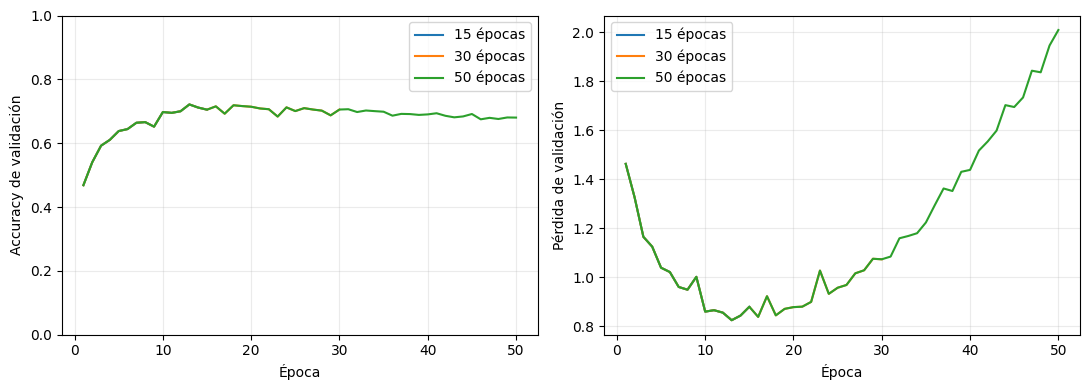

In [8]:
seleccionado=tabla.sort_values('val_loss').iloc[0]['experimento']
print('Elegido por validación antes del test:',seleccionado)
pruebas=[]; probabilidades=None
for nombre in tabla['experimento']:
    resultado,prob=evaluar(nombre,test_images,test_labels,CARPETA)
    pruebas.append(resultado)
    if nombre==seleccionado: probabilidades=prob
test_df=pd.DataFrame(pruebas)
test_df.to_csv(CARPETA/'evaluacion_prueba.csv',index=False)
display(tabla.merge(test_df,on='experimento'))
historiales={int(r['epocas']):json.loads((CARPETA/f"{r['experimento']}_historia.json").read_text())
             for r in registros}
fig,ax=plt.subplots(1,2,figsize=(11,4))
for ep,h in historiales.items():
    ax[0].plot(range(1,ep+1),h['val_accuracy'],label=f'{ep} épocas')
    ax[1].plot(range(1,ep+1),h['val_loss'],label=f'{ep} épocas')
ax[0].set(xlabel='Época',ylabel='Accuracy de validación',ylim=(0,1))
ax[1].set(xlabel='Época',ylabel='Pérdida de validación')
for a in ax: a.legend(); a.grid(alpha=.25)
fig.tight_layout();fig.savefig(CARPETA/'comparacion_duraciones.png',dpi=180);plt.show()


## 2.3.g Predicciones e interpretación
Softmax transforma los logits del modelo elegido en probabilidades. La clase predicha es su argmax;
la probabilidad máxima expresa confianza del modelo y no garantiza que la etiqueta sea correcta.
Se muestran 25 casos en orden fijo y se examinan errores y confusiones entre clases en todo el test.


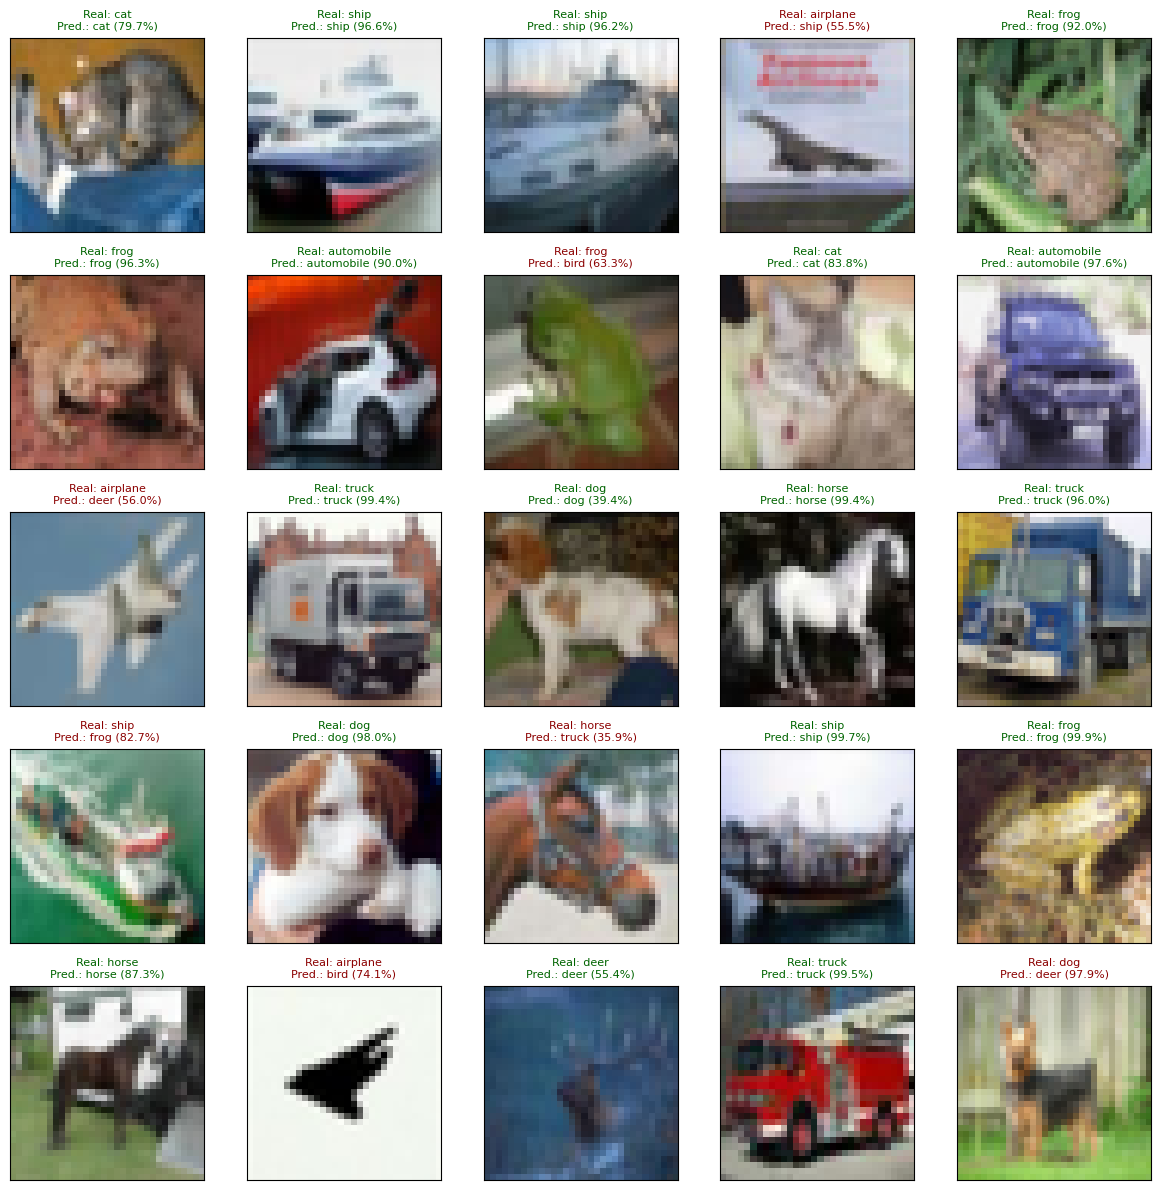

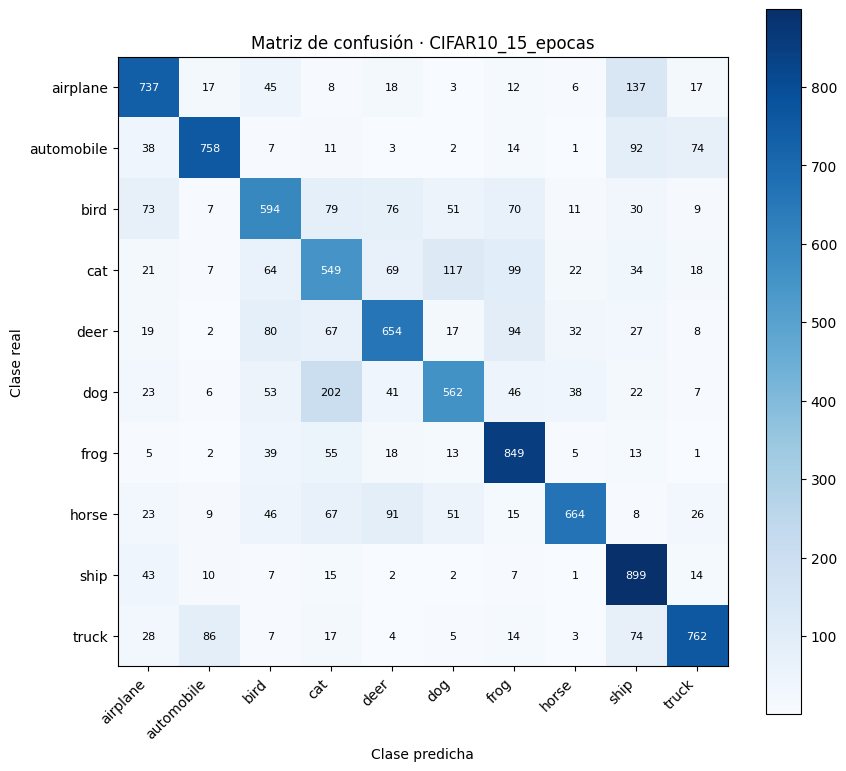

Imagen 3: real=airplane, predicha=ship, confianza=55.47%
Imagen 7: real=frog, predicha=bird, confianza=63.32%
Imagen 10: real=airplane, predicha=deer, confianza=56.02%
Imagen 15: real=ship, predicha=frog, confianza=82.66%
Imagen 17: real=horse, predicha=truck, confianza=35.92%


,clase,accuracy_clase
0,airplane,0.737
1,automobile,0.758
2,bird,0.594
3,cat,0.549
4,deer,0.654
5,dog,0.562
6,frog,0.849
7,horse,0.664
8,ship,0.899
9,truck,0.762


El modelo seleccionado por menor pérdida final de validación fue CIFAR10_15_epocas. En prueba obtuvo accuracy=0.7028 y loss=0.8837. La confusión más frecuente fue dog → cat (202 casos). Estos resultados corresponden a una partición y semilla; la selección no se hizo sobre el test.
Resultados guardados: /content/Actividad_Integradora/CIFAR10.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
y_real=test_labels.reshape(-1)
y_pred=probabilidades.argmax(axis=1)
fig,axs=plt.subplots(5,5,figsize=(12,12))
for i,ax in enumerate(axs.flat):
    ax.imshow(test_images[i]);ax.set_xticks([]);ax.set_yticks([])
    color='darkgreen' if y_pred[i]==y_real[i] else 'darkred'
    ax.set_title(f'Real: {class_names[y_real[i]]}\nPred.: {class_names[y_pred[i]]} ({probabilidades[i,y_pred[i]]:.1%})',
                 fontsize=8,color=color)
fig.tight_layout();fig.savefig(CARPETA/'predicciones_25.png',dpi=180);plt.show()

matriz=np.zeros((10,10),dtype=int)
np.add.at(matriz,(y_real,y_pred),1)
pd.DataFrame(matriz,index=class_names,columns=class_names).to_csv(CARPETA/'matriz_confusion.csv')
fig,ax=plt.subplots(figsize=(9,8))
im=ax.imshow(matriz,cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j,i,str(matriz[i,j]),ha='center',va='center',fontsize=8,
                color='white' if matriz[i,j]>matriz.max()/2 else 'black')
ax.set(xticks=range(10),yticks=range(10),xticklabels=class_names,yticklabels=class_names,
       xlabel='Clase predicha',ylabel='Clase real',title=f'Matriz de confusión · {seleccionado}')
plt.setp(ax.get_xticklabels(),rotation=45,ha='right');fig.colorbar(im,ax=ax)
fig.tight_layout();fig.savefig(CARPETA/'matriz_confusion.png',dpi=180);plt.show()

errores=np.flatnonzero(y_pred!=y_real)
for i in errores[:5]:
    print(f'Imagen {i}: real={class_names[y_real[i]]}, predicha={class_names[y_pred[i]]}, '
          f'confianza={probabilidades[i,y_pred[i]]:.2%}')
exactitud_clase=np.diag(matriz)/matriz.sum(axis=1)
display(pd.DataFrame({'clase':class_names,'accuracy_clase':exactitud_clase}))
sin_diagonal=matriz.copy();np.fill_diagonal(sin_diagonal,0)
real,pred=np.unravel_index(np.argmax(sin_diagonal),sin_diagonal.shape)
elegido_test=test_df.set_index('experimento').loc[seleccionado]
conclusion=(f"El modelo seleccionado por menor pérdida final de validación fue {seleccionado}. "
            f"En prueba obtuvo accuracy={elegido_test['test_accuracy']:.4f} y loss={elegido_test['test_loss']:.4f}. "
            f"La confusión más frecuente fue {class_names[real]} → {class_names[pred]} ({matriz[real,pred]} casos). "
            "Estos resultados corresponden a una partición y semilla; la selección no se hizo sobre el test.")
print(conclusion)
(CARPETA/'conclusion.txt').write_text(conclusion,encoding='utf-8')
exportar(CARPETA)


## Fuentes
- Krizhevsky, A., Nair, V., y Hinton, G. (s. f.). *The CIFAR-10 dataset*. https://www.cs.toronto.edu/~kriz/cifar.html
- TensorFlow. (s. f.). *Convolutional Neural Network (CNN)*. https://www.tensorflow.org/tutorials/images/cnn
- Cátedra de Sistemas Inteligentes. (2026). *Sistemas Inteligentes Actividad Integradora*. Universidad CAECE.
